## Import

In [2]:
import pickle
import json

import pandas as pd

from pathlib import Path

## Path

In [3]:
ROOT = Path("..")

TRAIN_PATH = ROOT / "data" / "processed" / "train.csv"

TRANSE_PATH = (
    ROOT /
    "models" /
    "transe" /
    "transe_model_full_train.pkl"
)

CATBOOST_PATH = (
    ROOT /
    "models" /
    "catboost" /
    "catboost_final.cbm"
)

ENCODER_DIR = (
    ROOT /
    "models" /
    "encoders"
)

ENCODER_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Path siap.")

Path siap.


## Definisi Pipeline

In [4]:
TARGET = "dev_status"

ORIGINAL_FEATURES = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

CATEGORICAL_FEATURES = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

NUMERIC_FEATURES = [
    "weight",
    "height",
    "age"
]

KGE_DIM = 100

RELATION_MAP = {
    "weight": "has_weight",
    "height": "has_height",
    "age": "has_age",
    "gross_motor": "has_gross_motor",
    "fine_motor_adaptive": "has_fine_motor_adaptive",
    "language": "has_language",
    "personal_social": "has_personal_social"
}

KGE_COLUMNS = [
    f"kge_{i}"
    for i in range(1, 101)
]

FINAL_FEATURES = (
    ORIGINAL_FEATURES +
    KGE_COLUMNS
)

assert len(ORIGINAL_FEATURES) == 7
assert len(KGE_COLUMNS) == 100
assert len(FINAL_FEATURES) == 107
assert TARGET not in FINAL_FEATURES

print("Total final features:", len(FINAL_FEATURES))

Total final features: 107


## Ambil Referensi Nilai TRAIN

In [5]:
train_df = pd.read_csv(
    TRAIN_PATH
)

numeric_reference_values = {}

for feature in NUMERIC_FEATURES:

    numeric_reference_values[feature] = sorted(
        train_df[feature]
        .astype(float)
        .unique()
        .tolist()
    )

print(
    "Reference values berhasil dibuat."
)

for feature, values in numeric_reference_values.items():

    print(
        feature,
        "->",
        len(values),
        "unique values"
    )

Reference values berhasil dibuat.
weight -> 18 unique values
height -> 71 unique values
age -> 6 unique values


- weight -> 18 → ada 18 nilai berat badan berbeda di train.
- height -> 71 → ada 71 nilai tinggi badan berbeda di train.
- age -> 6 → ada 6 nilai usia berbeda, yaitu 0–5.

## Simpan Konfigurasi Pipeline

In [6]:
pipeline_config = {

    "original_features":
        ORIGINAL_FEATURES,

    "categorical_features":
        CATEGORICAL_FEATURES,

    "numeric_features":
        NUMERIC_FEATURES,

    "kge_columns":
        KGE_COLUMNS,

    "final_features":
        FINAL_FEATURES,

    "target":
        TARGET,

    "kge_dimension":
        KGE_DIM,

    "relation_map":
        RELATION_MAP,

    "numeric_reference_values":
        numeric_reference_values,

    "model":
        "CatBoost + TransE",

    "embedding_method":
        "TransE",

    "feature_integration":
        "concatenation",

    "random_seed":
        42
}

CONFIG_PATH = (
    ENCODER_DIR /
    "pipeline_config.pkl"
)

with open(
    CONFIG_PATH,
    "wb"
) as f:

    pickle.dump(
        pipeline_config,
        f
    )

print(
    "Pipeline config saved:"
)

print(
    CONFIG_PATH
)

Pipeline config saved:
..\models\encoders\pipeline_config.pkl


## Verifikasi Model

In [7]:
assert TRANSE_PATH.exists(), (
    "TransE model tidak ditemukan."
)

assert CATBOOST_PATH.exists(), (
    "CatBoost final tidak ditemukan."
)

assert CONFIG_PATH.exists(), (
    "Pipeline config tidak ditemukan."
)

print("===== PIPELINE ARTIFACT CHECK =====")

print(
    "TransE :",
    TRANSE_PATH.exists()
)

print(
    "CatBoost:",
    CATBOOST_PATH.exists()
)

print(
    "Config  :",
    CONFIG_PATH.exists()
)

print(
    "\n✅ Semua artifact pipeline tersedia."
)

===== PIPELINE ARTIFACT CHECK =====
TransE : True
CatBoost: True
Config  : True

✅ Semua artifact pipeline tersedia.


## Test

In [8]:
import sys

sys.path.append(
    str(ROOT)
)

from src.prediction_pipeline import (
    ChildDevelopmentPipeline
)

pipeline = ChildDevelopmentPipeline(
    ROOT
)

print(
    "✅ Pipeline berhasil dimuat."
)

✅ Pipeline berhasil dimuat.


In [9]:
# Data asli anak
weight = 15
height = 80
age_category = 2

# Normalisasi sesuai app.py
test_sample = {
    "weight": min(1.0, max(0.0, (weight - 3.0) / 17.0)),
    "height": min(1.0, max(0.0, (height - 50.0) / 70.0)),
    "age": age_category / 5.0,
    "gross_motor": "advanced",
    "fine_motor_adaptive": "advanced",
    "language": "normal",
    "personal_social": "delayed"
}

prediction = pipeline.predict(test_sample)
probability = pipeline.predict_proba(test_sample)

print("Input model:", test_sample)
print("Prediction:", prediction)
print("Probability:", probability)

Input model: {'weight': 0.7058823529411765, 'height': 0.42857142857142855, 'age': 0.4, 'gross_motor': 'advanced', 'fine_motor_adaptive': 'advanced', 'language': 'normal', 'personal_social': 'delayed'}
Prediction: ['suspect']
Probability: [[0.04765262 0.95234738]]


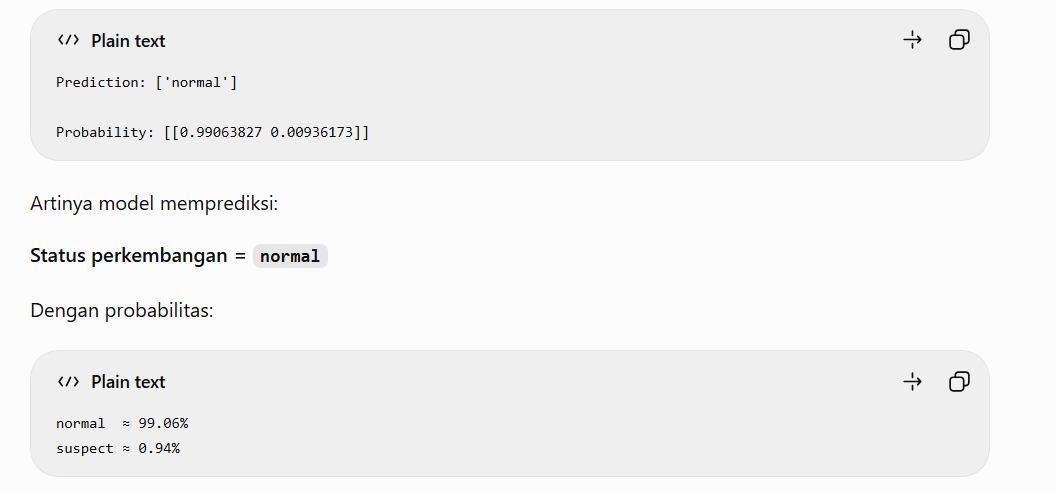